# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [3]:
from google.colab import files #load in data
uploaded = files.upload()

Saving pierce_county_house_sales.csv to pierce_county_house_sales.csv


In [4]:
# q1 - cleaning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('pierce_county_house_sales.csv')
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

# All dates are from 2020
df['sale_date'] = pd.to_datetime(df['sale_date'])
df['sale_month'] = df['sale_date'].dt.month

# Waterfront type NA means not waterfront
# View quality NA means no rated view
df['waterfront_type'] = df['waterfront_type'].fillna('Not waterfront')
df['view_quality'] = df['view_quality'].fillna('None')

# drop the rest of the NA rows
df = df.dropna()
print()
print('NA after drops:', df.isna().sum())
print()

# Check for duplicates
print(f'duplicated rows: {df.duplicated().sum()}')
df = df.drop_duplicates()
print(f'duplicated rows after drop: {df.duplicated().sum()}')

print()
print(df.describe())

# Some unrealistic values - drop
df = df[df['sale_price'] >= 50000]
df = df[df['house_square_feet'] >= 100]
df = df[df['bedrooms'] > 0]
df = df[df['bathrooms'] > 0]
df = df[df['stories'] > 0]
print()
print('Cleaned shape:', df.shape)
print()

num_vars = ['sale_price', 'house_square_feet', 'attic_finished_square_feet', 'basement_square_feet',
            'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built',
            'bedrooms', 'bathrooms']
cat_vars = ['hvac_description', 'exterior', 'interior', 'roof_cover', 'waterfront_type', 'view_quality', 'utility_sewer']
print(df[num_vars].describe().T)
for c in cat_vars:
  print(df[c].value_counts(), '\n')




(16814, 19)
sale_date                      object
sale_price                      int64
house_square_feet               int64
attic_finished_square_feet      int64
basement_square_feet            int64
attached_garage_square_feet     int64
detached_garage_square_feet     int64
fireplaces                      int64
hvac_description               object
exterior                       object
interior                       object
stories                         int64
roof_cover                     object
year_built                      int64
bedrooms                        int64
bathrooms                       int64
waterfront_type                object
view_quality                   object
utility_sewer                  object
dtype: object
sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet   

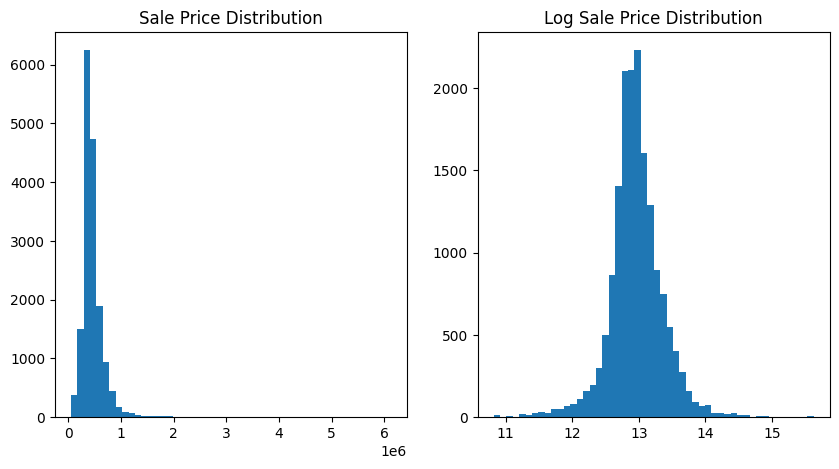

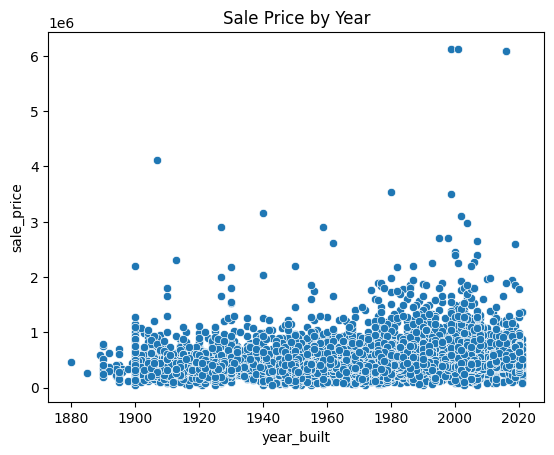

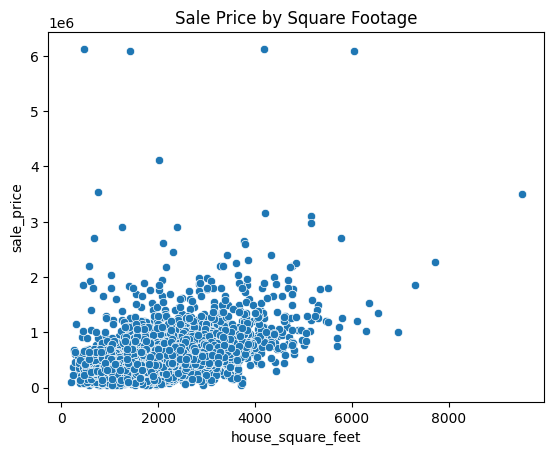

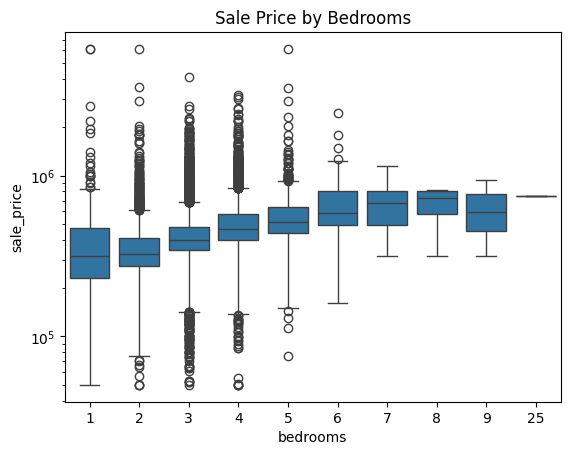

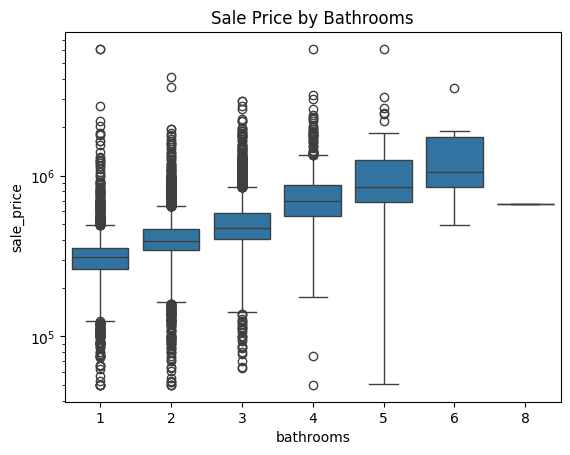

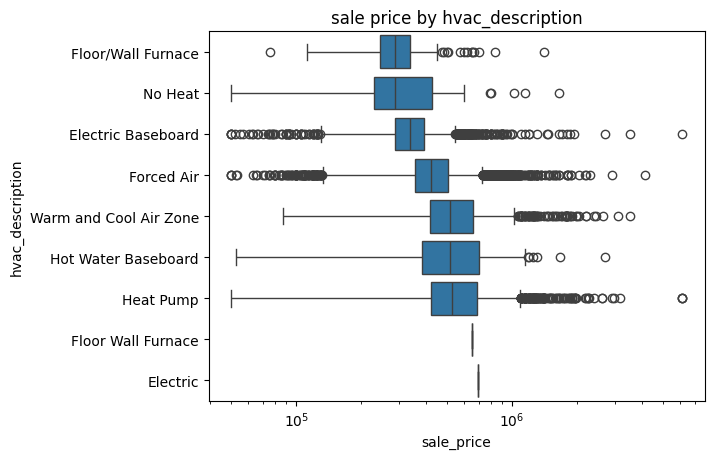

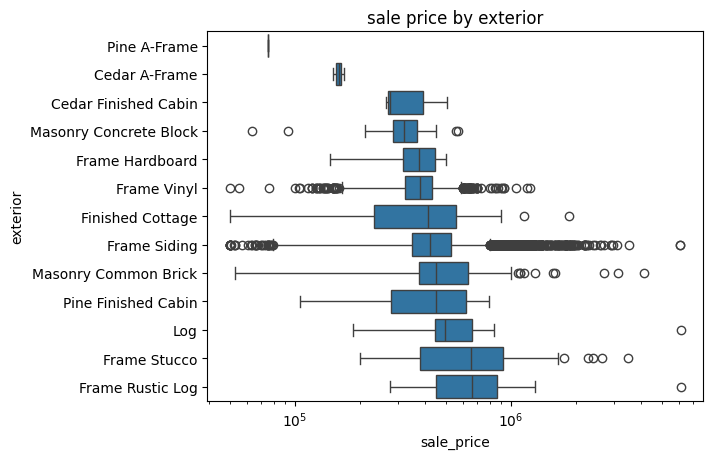

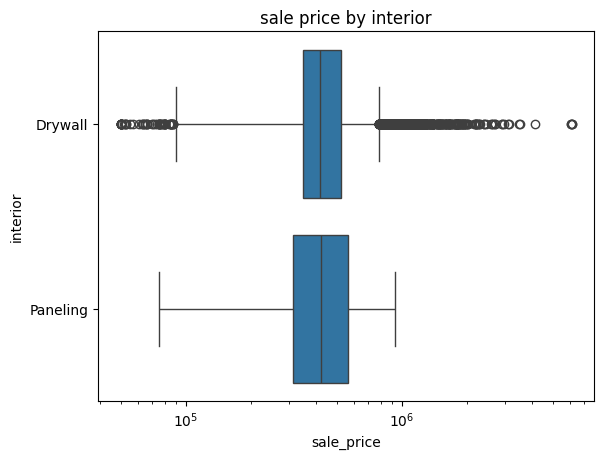

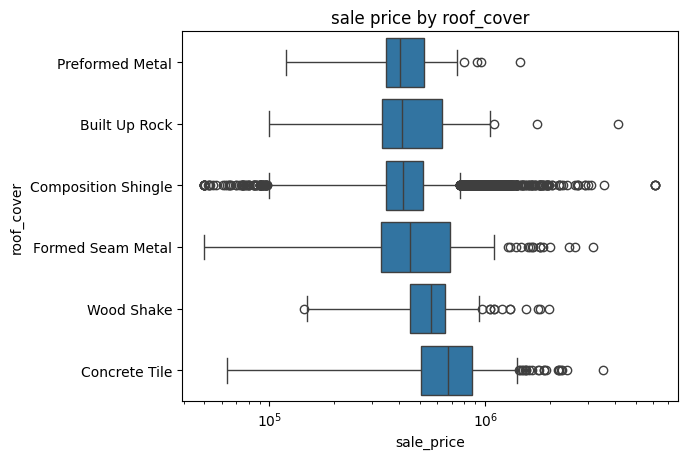

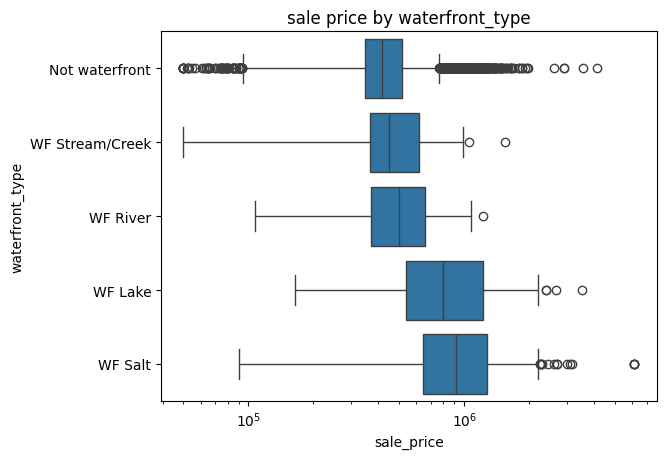

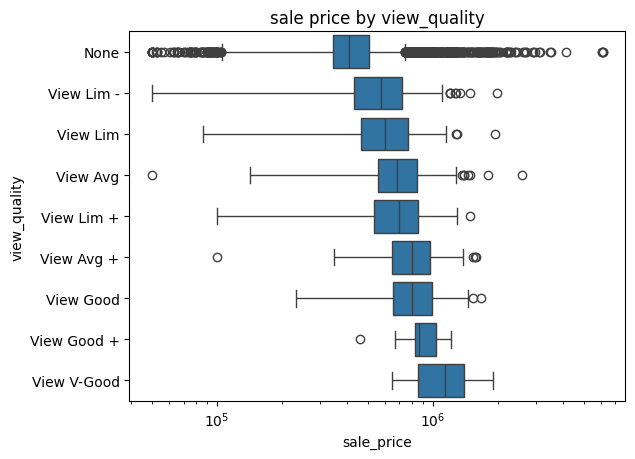

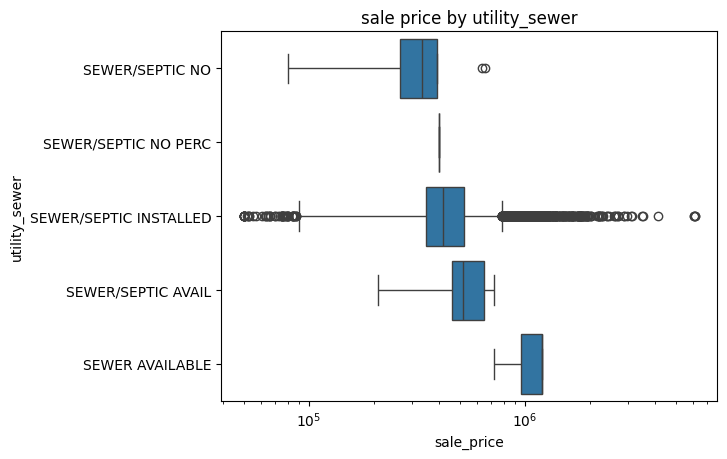

In [5]:
from matplotlib import axes
# q1 Visualization

# Sale price distribution
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
df['sale_price'].hist(bins=50, grid=False, ax=axes[0])
axes[0].set_title('Sale Price Distribution')
np.log(df['sale_price']).hist(bins=50, grid=False, ax=axes[1]) # Sale price is skewed right, graph log transformation
axes[1].set_title('Log Sale Price Distribution')
plt.show()

# Sale price by year
sns.scatterplot(data=df, x='year_built', y='sale_price')
plt.title('Sale Price by Year')
plt.show()

# Sale price by square footage
sns.scatterplot(data=df, x='house_square_feet', y='sale_price')
plt.title('Sale Price by Square Footage')
plt.show()

# Sale price by bedrooms
sns.boxplot(data=df, x='bedrooms', y='sale_price')
plt.title('Sale Price by Bedrooms')
plt.yscale('log')
plt.show()

# Sale price by bathrooms
sns.boxplot(data=df, x='bathrooms', y='sale_price')
plt.yscale('log') # Box plots are skewed heavily by high sale prices - log transform them
plt.title('Sale Price by Bathrooms')
plt.show()

# Price by categorical Features
for c in cat_vars:
  order = df.groupby(c)['sale_price'].median().sort_values().index
  sns.boxplot(data=df, y=c, x='sale_price', order=order)
  plt.xscale('log')
  plt.title(f'sale price by {c}')
  plt.show()

In [6]:
# q2
t_df = df.copy()

# transform skewed numerical values
t_df['log_price'] = np.log(t_df['sale_price'])
t_df['log_sqft'] = np.log(t_df['house_square_feet'])
t_df['age'] = 2020 - t_df['year_built']

# Assign 1 or 0 for features that houses either have or don't have
t_df['has_basement'] = (t_df['basement_square_feet'] > 0).astype(int)
t_df['has_attic'] = (t_df['attic_finished_square_feet'] > 0).astype(int)
t_df['has_attached_garage'] = (t_df['attached_garage_square_feet'] > 0).astype(int)
t_df['has_detached_garage'] = (t_df['detached_garage_square_feet'] > 0).astype(int)

# Simplify waterfront to yes or no
t_df['waterfront'] = (t_df['waterfront_type'] != 'Not waterfront').astype(int)

# Map views to a score rating
view_map = {'None': 0, 'View Lim -': 1, 'View Lim': 2, 'View Lim +': 3,
            'View Avg': 4, 'View Avg +': 5, 'View Good': 6, 'View Good +': 7, 'View V-Good': 8}
t_df['view_score'] = t_df['view_quality'].map(view_map)

# Keep main exterior values, lump rest into 'other'
def exterior_group(type):
  if type in ['Frame Siding', 'Frame Vinyl', 'Frame Stucco']:
    return type
  if type.startswith('Masonry'):
    return 'Masonry'
  else:
    return 'Other'
t_df['exterior_group'] = t_df['exterior'].apply(exterior_group)

# Group rare HVAC types into 'other'
t_df['hvac_group'] = t_df['hvac_description'].replace(
    {'Electric': 'Other', 'No Heat': 'Other', 'Hot Water Baseboard': 'Other',
     'Floor/Wall Furnace': 'Other', 'Floor Wall Furnace': 'Other'}
)

# Group interior by drywall or not
t_df['drywall'] = (t_df['interior'] == 'Drywall').astype(int)

# simplify sewer to yes/no
t_df['sewer_installed'] = (t_df['utility_sewer'] == 'SEWER/SEPTIC INSTALLED').astype(int)

# Turn remaining categories into 0/1
dummies = pd.get_dummies(t_df[['roof_cover', 'exterior_group', 'hvac_group', 'waterfront_type']], drop_first=True, dtype = int)

# Month Dummies
month_dummies = pd.get_dummies(t_df['sale_month'], prefix='month', drop_first=True, dtype = int)

numerics = ['house_square_feet', 'log_sqft', 'attic_finished_square_feet',
            'basement_square_feet', 'attached_garage_square_feet',
            'detached_garage_square_feet', 'fireplaces', 'stories',
            'age', 'bedrooms', 'bathrooms', 'has_basement', 'has_attic',
            'has_attached_garage', 'has_detached_garage', 'view_score',
            'sewer_installed', 'drywall']

X = pd.concat([t_df[numerics], dummies, month_dummies], axis=1)
y = t_df['log_price']

print(X.shape)
print(X.columns.tolist())
X.head().T





(16646, 46)
['house_square_feet', 'log_sqft', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'age', 'bedrooms', 'bathrooms', 'has_basement', 'has_attic', 'has_attached_garage', 'has_detached_garage', 'view_score', 'sewer_installed', 'drywall', 'roof_cover_Composition Shingle', 'roof_cover_Concrete Tile', 'roof_cover_Formed Seam Metal', 'roof_cover_Preformed Metal', 'roof_cover_Wood Shake', 'exterior_group_Frame Stucco', 'exterior_group_Frame Vinyl', 'exterior_group_Masonry', 'exterior_group_Other', 'hvac_group_Forced Air', 'hvac_group_Heat Pump', 'hvac_group_Other', 'hvac_group_Warm and Cool Air Zone', 'waterfront_type_WF Lake', 'waterfront_type_WF River', 'waterfront_type_WF Salt', 'waterfront_type_WF Stream/Creek', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12']


,0,1,2,3,4
house_square_feet,2157.000000,2238.000000,1452.000000,832.000000,1780.000000
log_sqft,7.676474,7.713338,7.280697,6.723832,7.484369
attic_finished_square_feet,0.000000,0.000000,0.000000,0.000000,0.000000
basement_square_feet,0.000000,0.000000,0.000000,0.000000,384.000000
attached_garage_square_feet,528.000000,396.000000,0.000000,0.000000,484.000000
detached_garage_square_feet,0.000000,0.000000,0.000000,0.000000,0.000000
fireplaces,0.000000,0.000000,1.000000,0.000000,1.000000
stories,2.000000,2.000000,1.000000,1.000000,1.000000
age,27.000000,3.000000,55.000000,101.000000,65.000000
bedrooms,3.000000,4.000000,3.000000,2.000000,3.000000


In [7]:
#q3-80/20 test/train split
from sklearn.model_selection import train_test_split

y = t_df['sale_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=1)
print("Train: ", len(y_train))
print("Test: ", len(y_test))



Train:  13316
Test:  3330


Test data set (3,330 houses) set aside

In [8]:
#q4-simple linear models without transformations or interactions
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

#Model 1 (house size)
fit_1 = LinearRegression().fit(X_train[['house_square_feet']], y_train)

train_pred_1 = fit_1.predict(X_train[['house_square_feet']])
test_pred_1 = fit_1.predict(X_test[['house_square_feet']])

train_rmse_1 = root_mean_squared_error(y_train, train_pred_1)
test_rmse_1 = root_mean_squared_error(y_test, test_pred_1)

train_r2_1 = r2_score(y_train, train_pred_1)
test_r2_1 = r2_score(y_test, test_pred_1)

print("Model 1")
print('Train RMSE: ', train_rmse_1)
print('Test RMSE: ', test_rmse_1)
print('Train R2: ', train_r2_1)
print('Test R2: ', test_r2_1)


#Model 2 (house size, bathrooms, bedrooms)
fit_2 = LinearRegression().fit(X_train[['house_square_feet', 'bathrooms', 'bedrooms']], y_train)

train_pred_2 = fit_2.predict(X_train[['house_square_feet', 'bathrooms', 'bedrooms']])
test_pred_2 = fit_2.predict(X_test[['house_square_feet', 'bathrooms', 'bedrooms']])

train_rmse_2 = root_mean_squared_error(y_train, train_pred_2)
test_rmse_2 = root_mean_squared_error(y_test, test_pred_2)

train_r2_2 = r2_score(y_train, train_pred_2)
test_r2_2 = r2_score(y_test, test_pred_2)

print('')
print("Model 2")
print('Train RMSE: ', train_rmse_2)
print('Test RMSE: ', test_rmse_2)
print('Train R2: ', train_r2_2)
print('Test R2: ', test_r2_2)



Model 1
Train RMSE:  198015.62506939235
Test RMSE:  181198.62787718684
Train R2:  0.28508333930268437
Test R2:  0.3220389964419307

Model 2
Train RMSE:  195349.1595414846
Test RMSE:  179272.52781512676
Train R2:  0.30420774496772485
Test R2:  0.33637553373322304


Model 2 is the better model, as it has a lower test RMSE (181198.62 for Model 1 vs 179272.53 for Model 2) and a higher test R^2 (.336 vs .322). The differences in the models is small however which can likely be attributed to bedrooms and bathrooms already being correlated with square footage. The train and test scores for both models are similar, indicating there is no overfitting.

Residual slope:  175.2429120944513
Square feet coefficient:  175.24291209442825


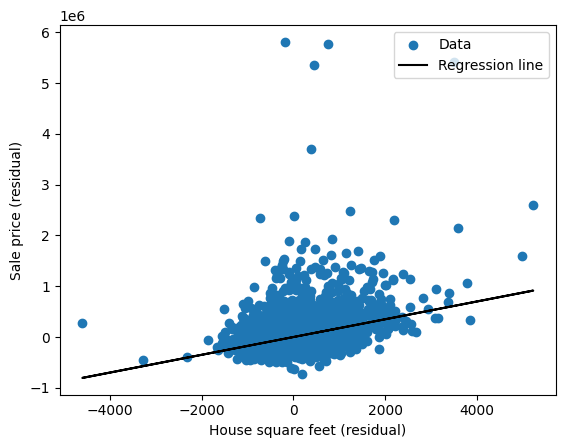

In [9]:
#q5-Partial regression plots for numerical variables in Model 2

#slr function
def slr(x, y):
  x_bar, y_bar = np.mean(x), np.mean(y)
  b1 = np.inner(x-x_bar, y-y_bar) / np.inner(x-x_bar, x-x_bar)
  b0 = y_bar - b1 * x_bar
  y_hat = b0 + b1 * x
  return {'b0': b0, 'b1': b1, 'y_hat': y_hat, 'residuals': y-y_hat}


sqft = X_train['house_square_feet']
price = y_train

r_price = price - LinearRegression().fit(X_train[['bedrooms', 'bathrooms']], price).predict(X_train[['bedrooms', 'bathrooms']])
r_sqft = sqft - LinearRegression().fit(X_train[['bedrooms', 'bathrooms']], sqft).predict(X_train[['bedrooms', 'bathrooms']])

partial_fit = slr(r_sqft, r_price)
print('Residual slope: ', partial_fit['b1'])
print('Square feet coefficient: ', fit_2.coef_[0])

plt.scatter(r_sqft, r_price, label = "Data")
plt.plot(r_sqft, partial_fit['y_hat'], color = 'black', label = "Regression line")
plt.xlabel("House square feet (residual)")
plt.ylabel("Sale price (residual)")
plt.legend(loc = "upper right")
plt.show()







It looks like square footage has a positive relationship with sale price (after accounting for bedrooms and bathrooms). However, the relationship is not strictly linear: as the sqft increases, price spreads.

Residual slope:  25400.581353307418
Bathrooms coefficient:  25400.581353307425


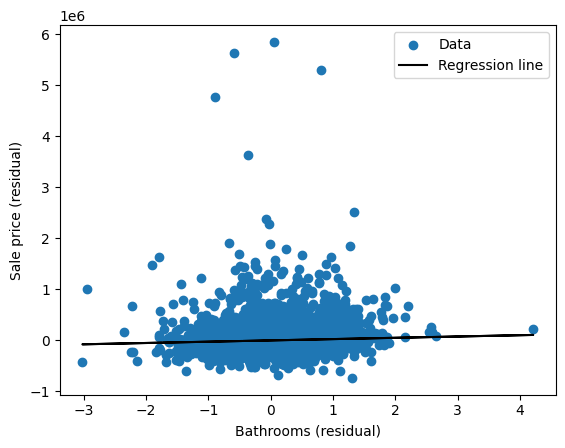

In [10]:
baths = X_train['bathrooms']
price = y_train

r_price = price - LinearRegression().fit(X_train[['bedrooms', 'house_square_feet']], price).predict(X_train[['bedrooms', 'house_square_feet']])
r_baths = baths - LinearRegression().fit(X_train[['bedrooms', 'house_square_feet']], baths).predict(X_train[['bedrooms', 'house_square_feet']])

partial_fit = slr(r_baths, r_price)
print('Residual slope: ', partial_fit['b1'])
print('Bathrooms coefficient: ', fit_2.coef_[1])

plt.scatter(r_baths, r_price, label = "Data")
plt.plot(r_baths, partial_fit['y_hat'], color = 'black', label = "Regression line")
plt.xlabel("Bathrooms (residual)")
plt.ylabel("Sale price (residual)")
plt.legend(loc = "upper right")
plt.show()

The relationship between bathrooms and sales price is nearly flat (after accounting for sqft and bedrooms), and no clear non-linearities. Additionally, the spread appears even throughout. Bathrooms add little info beyond house size. There also appears to be a few outliers.

Residual slope:  -45856.56096875299
Bedrooms coefficient:  -45856.56096875301


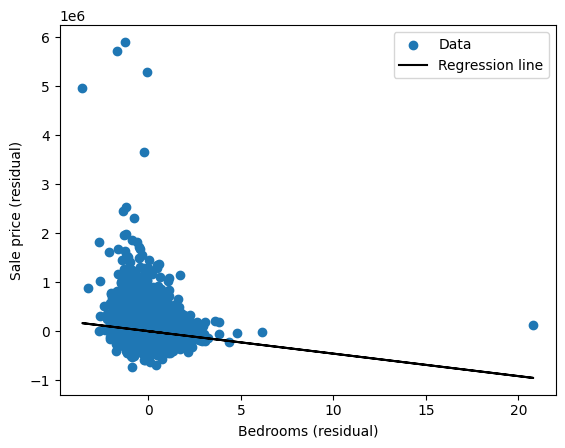

In [11]:
beds = X_train['bedrooms']
price = y_train

r_price = price - LinearRegression().fit(X_train[['house_square_feet', 'bathrooms']], price).predict(X_train[['house_square_feet', 'bathrooms']])
r_beds = beds - LinearRegression().fit(X_train[['house_square_feet', 'bathrooms']], beds).predict(X_train[['house_square_feet', 'bathrooms']])

partial_fit = slr(r_beds, r_price)
print('Residual slope: ', partial_fit['b1'])
print('Bedrooms coefficient: ', fit_2.coef_[2])

plt.scatter(r_beds, r_price, label = "Data")
plt.plot(r_beds, partial_fit['y_hat'], color = 'black', label = "Regression line")
plt.xlabel("Bedrooms (residual)")
plt.ylabel("Sale price (residual)")
plt.legend(loc = "upper right")
plt.show()

The relationship between sales price and bedroom (after acounting for bathrooms and sqft) displays a slightly downward, negative slope, indicating more bedrooms are associated with a lower price. However, the large spread indicates this relationship is weak and not very linear. There appears to be one strong outlier with over 20 bedrooms.

Overall, the house square footage shows the main non-linearity, as price spreads more when sqft increases, and a few very expensive houses are way above the regression line in all 3 plots.


In [14]:
# q6
from sklearn.model_selection import KFold, cross_val_score

def build_features(X):
    Z = X.copy()

    # use log of sqr ft + squared term for curve
    Z = Z.drop(columns=['house_square_feet'])
    Z['log_sqft_sq'] = Z['log_sqft'] ** 2

    # Secondary areas are skewed with many zeros, so use IHS
    for c in ['basement_square_feet', 'attic_finished_square_feet',
              'attached_garage_square_feet', 'detached_garage_square_feet']:
        Z['ihs_' + c] = np.arcsinh(Z[c])
        Z = Z.drop(columns=c)

    # Age can be nonlinear
    Z['age_sq'] = Z['age'] ** 2

    # Cap extreme counts (the 25 bedroom house lol), then let rooms snd age interact with size
    Z['bedrooms'] = Z['bedrooms'].clip(upper=8)
    Z['bathrooms'] = Z['bathrooms'].clip(upper=6)
    Z['beds_x_logsqft'] = Z['bedrooms'] * Z['log_sqft']
    Z['baths_x_logsqft'] = Z['bathrooms'] * Z['log_sqft']
    Z['age_x_logsqft'] = Z['age'] * Z['log_sqft']

    # Waterfront indicator used only inside interactions
    # dummy variable trap here so need to be careful
    wf_cols = [c for c in Z.columns if c.startswith('waterfront_type_')]
    any_wf = Z[wf_cols].sum(axis=1)
    Z['view_x_wf'] = Z['view_score'] * any_wf
    Z['logsqft_x_wf'] = Z['log_sqft'] * any_wf
    Z['logsqft_x_view'] = Z['log_sqft'] * Z['view_score']
    return Z

X_train_c = build_features(X_train)
X_test_c = build_features(X_test)


def evaluate(name, Xtr, Xte, log_target=False):
    model = LinearRegression()
    if log_target:
        model.fit(Xtr, np.log(y_train))
        # Convert predictions back to dollars (exp undoes log)
        tr_pred = np.exp(model.predict(Xtr))
        te_pred = np.exp(model.predict(Xte))
    else:
        model.fit(Xtr, y_train)
        tr_pred, te_pred = model.predict(Xtr), model.predict(Xte)
    return {'Model': name,
            'Train RMSE': root_mean_squared_error(y_train, tr_pred),
            'Test RMSE': root_mean_squared_error(y_test, te_pred),
            'Train R2': r2_score(y_train, tr_pred),
            'Test R2': r2_score(y_test, te_pred),
            'n features': Xtr.shape[1]}, model

raw_cols = [c for c in X_train.columns if c != 'log_sqft']   # every feature, no transfromations
s1 = ['house_square_feet']
s2 = ['house_square_feet', 'bathrooms', 'bedrooms']

results = [evaluate('M1: sqft', X_train[s1], X_test[s1])[0],
           evaluate('M2: sqft, beds, baths', X_train[s2], X_test[s2])[0],
           evaluate('M3: all features, linear', X_train[raw_cols], X_test[raw_cols])[0],
           evaluate('M3b: all features, log price', X_train[raw_cols], X_test[raw_cols], log_target=True)[0]]
res4, fit_4 = evaluate('M4: logs + interactions', X_train_c, X_test_c, log_target=True)
results.append(res4)
print(pd.DataFrame(results).set_index('Model').round(3))

# Model selection with 5 fold CV on the training data only
folds = KFold(n_splits=5, shuffle=True, random_state=1)
for name, Xt in [('M3b', X_train[raw_cols]), ('M4', X_train_c)]:
    cv_rmse = -cross_val_score(LinearRegression(), Xt, np.log(y_train), cv=folds,
                               scoring='neg_root_mean_squared_error').mean()
    print(name, 'CV RMSE (log price):', round(cv_rmse, 4))



                              Train RMSE   Test RMSE  Train R2  Test R2  \
Model                                                                     
M1: sqft                      198015.625  181198.628     0.285    0.322   
M2: sqft, beds, baths         195349.160  179272.528     0.304    0.336   
M3: all features, linear      155790.986  142792.763     0.557    0.579   
M3b: all features, log price  157993.286  143248.493     0.545    0.576   
M4: logs + interactions       151154.788  139708.471     0.583    0.597   

                              n features  
Model                                     
M1: sqft                               1  
M2: sqft, beds, baths                  3  
M3: all features, linear              45  
M3b: all features, log price          45  
M4: logs + interactions               53  
M3b CV RMSE (log price): 0.2718
M4 CV RMSE (log price): 0.2689


I used log price and log square footage since prices spread out as homes get bigger, and added interactions so that features like bedrooms, view and waterfront can matter differently depending on house size. This model did the best, with a test RMSE of \$139,708 and an R^2 of 0.597, compared to $179,273 and 0.336 for Model 2 and \$142,793 and 0.579 for the all-features linear model. Most of the improvement came from adding more features, the transformations helped a bit more on top of that, and the train and test scores stayed close, so it isn’t overfitting.

In [13]:
#q7

The simple models underfit, explaining only about a third of price variation, with nearly the same train and test scores. Adding more features, logs and interactions raised test R² to 0.597 without any overfitting, but it leveled off around 0.6, probably because the data has zero location information. The main takeaway is that more features always improve training fit, so models should with cross validation.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]